In [0]:
%sql
WITH revenue_by_category AS (
    SELECT
        COALESCE(
            dp.product_category_name_english,
            'sem_categoria'
        ) AS categoria,
        SUM(fs.price) AS receita_total
    FROM olist_dw.dw.fact_sales fs
    LEFT JOIN olist_dw.dw.dim_product dp
        ON fs.product_sk = dp.product_sk
    GROUP BY
        COALESCE(
            dp.product_category_name_english,
            'sem_categoria'
        )
)

SELECT
    categoria,
    ROUND(receita_total, 2) AS receita_total,
    ROUND(
        100.0 * receita_total /
        SUM(receita_total) OVER (),
        2
    ) AS participacao_percentual
FROM revenue_by_category
ORDER BY receita_total DESC;


categoria,receita_total,participacao_percentual
health_beauty,1258681.34,9.26
watches_gifts,1205005.68,8.87
bed_bath_table,1036988.68,7.63
sports_leisure,988048.97,7.27
computers_accessories,911954.32,6.71
furniture_decor,729762.49,5.37
cool_stuff,635290.85,4.67
housewares,632248.66,4.65
auto,592720.11,4.36
garden_tools,485256.46,3.57


In [0]:
%sql
WITH freight_by_order AS (
    SELECT
        order_id,
        customer_sk,
        SUM(freight_value) AS frete_total_pedido
    FROM olist_dw.dw.fact_sales
    GROUP BY
        order_id,
        customer_sk
)

SELECT
    dc.customer_state AS estado,
    ROUND(AVG(fbo.frete_total_pedido), 2)
        AS frete_medio_por_pedido,
    COUNT(*) AS quantidade_pedidos
FROM freight_by_order fbo
INNER JOIN olist_dw.dw.dim_customer dc
    ON fbo.customer_sk = dc.customer_sk
GROUP BY dc.customer_state
ORDER BY frete_medio_por_pedido DESC;


estado,frete_medio_por_pedido,quantidade_pedidos
RR,48.59,46
PB,48.35,532
RO,46.22,247
AC,45.52,81
PI,43.04,493
MA,42.6,740
TO,42.05,279
AP,41.01,68
SE,40.9,345
PA,39.9,970


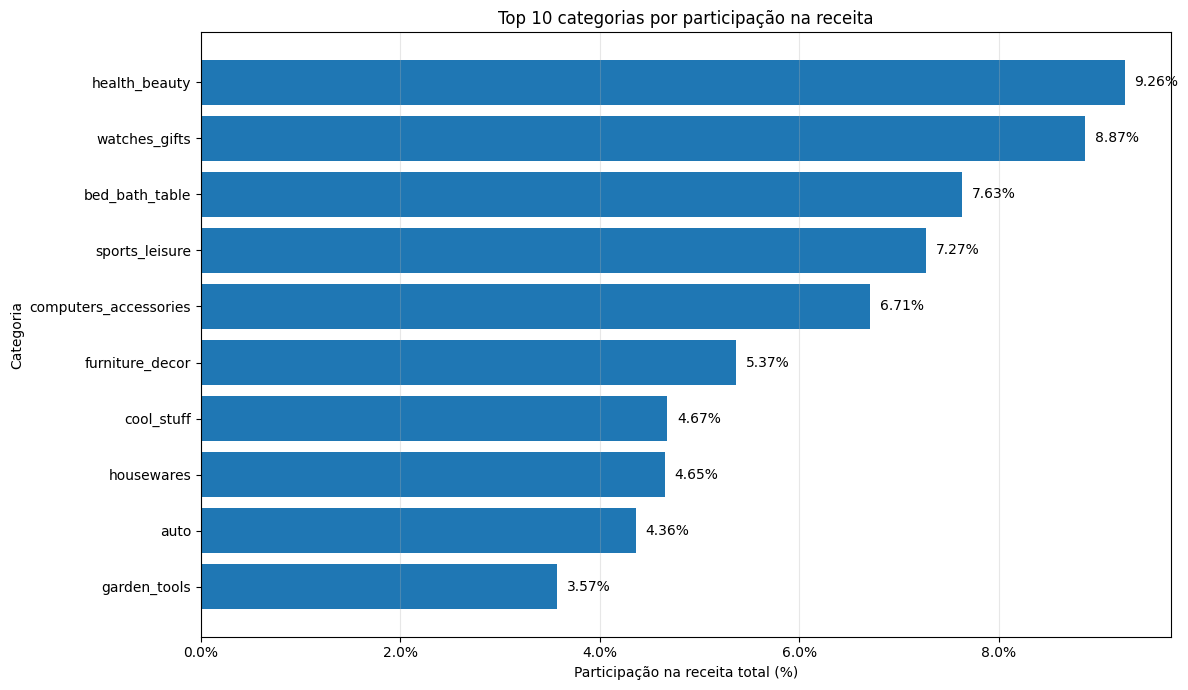

In [0]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

df_category_revenue = spark.sql("""
    WITH revenue_by_category AS (
        SELECT
            COALESCE(
                dp.product_category_name_english,
                'sem_categoria'
            ) AS categoria,
            SUM(fs.price) AS receita_total
        FROM olist_dw.dw.fact_sales fs
        LEFT JOIN olist_dw.dw.dim_product dp
            ON fs.product_sk = dp.product_sk
        GROUP BY 1
    )
    SELECT
        categoria,
        receita_total,
        100.0 * receita_total /
            SUM(receita_total) OVER () AS participacao
    FROM revenue_by_category
    ORDER BY receita_total DESC
    LIMIT 10
""").toPandas()

df_category_revenue = df_category_revenue.sort_values("participacao")

plt.figure(figsize=(12, 7))

bars = plt.barh(
    df_category_revenue["categoria"],
    df_category_revenue["participacao"]
)

plt.title("Top 10 categorias por participação na receita")
plt.xlabel("Participação na receita total (%)")
plt.ylabel("Categoria")

for bar in bars:
    plt.text(
        bar.get_width() + 0.1,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

plt.gca().xaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=100)
)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/Volumes/olist_dw/dw/silver_files/participacao_receita_categoria.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


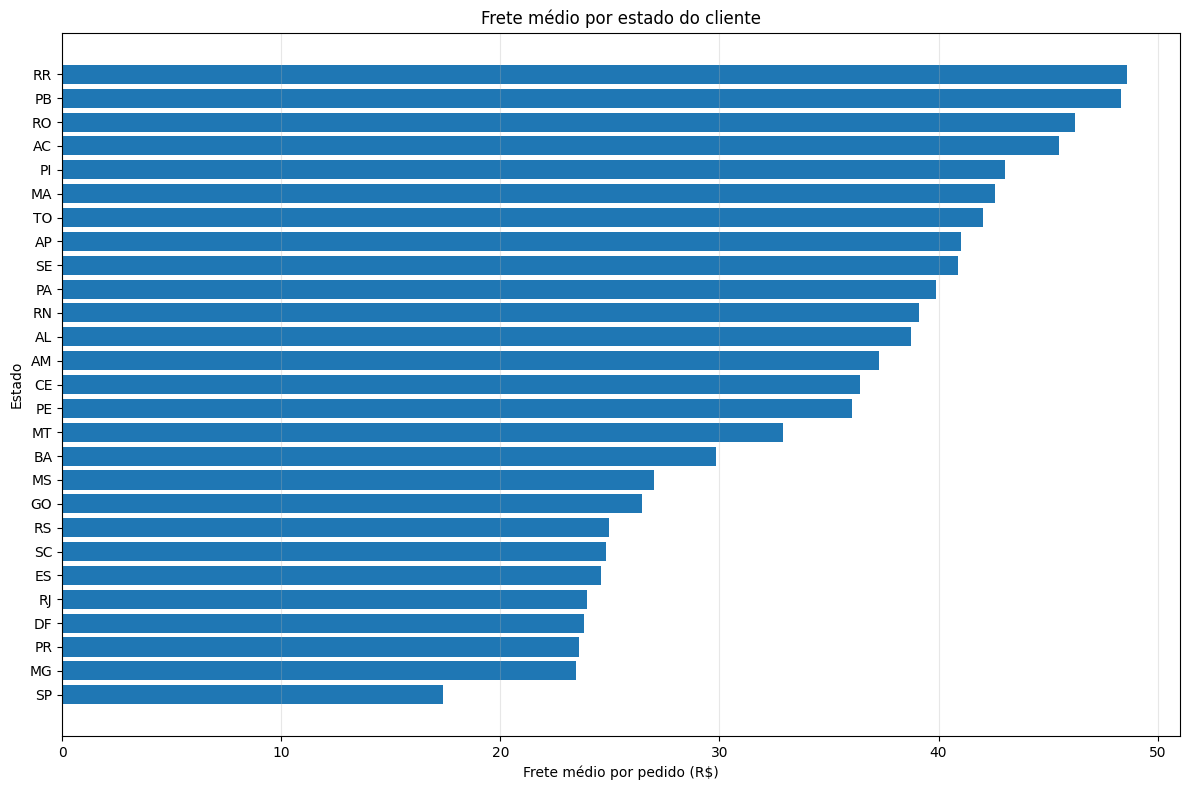

In [0]:

import matplotlib.pyplot as plt

df_freight = spark.sql("""
    WITH freight_by_order AS (
        SELECT
            order_id,
            customer_sk,
            SUM(freight_value) AS frete_total_pedido
        FROM olist_dw.dw.fact_sales
        GROUP BY order_id, customer_sk
    )
    SELECT
        dc.customer_state AS estado,
        AVG(fbo.frete_total_pedido) AS frete_medio_por_pedido,
        COUNT(*) AS quantidade_pedidos
    FROM freight_by_order fbo
    INNER JOIN olist_dw.dw.dim_customer dc
        ON fbo.customer_sk = dc.customer_sk
    GROUP BY dc.customer_state
    ORDER BY frete_medio_por_pedido
""").toPandas()

plt.figure(figsize=(12, 8))

plt.barh(
    df_freight["estado"],
    df_freight["frete_medio_por_pedido"]
)

plt.title("Frete médio por estado do cliente")
plt.xlabel("Frete médio por pedido (R$)")
plt.ylabel("Estado")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/Volumes/olist_dw/dw/silver_files/frete_medio_estado.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
